# 01 · Quick start: from raw reviews to a full report

This notebook shows the shortest path through **`steam-review-analysis`**: load scraped
Steam reviews, clean them into one typed dataset, and produce a complete before/after
analysis of one game with a single function call.

| Step | Package API | CLI equivalent |
|---|---|---|
| 1. Scrape | `steam_review_analysis.scraping` | `steam-review-analysis scrape <APP_ID>` |
| 2. Clean | `clean_reviews`, `write_processed` | `steam-review-analysis clean` |
| 3. Analyse | `analysis.report.run_analysis` | `steam-review-analysis analyse report` |

Scraping needs Chrome and takes a while, so this notebook starts from the review sample
that ships with the repository in `data/cleaned/`. Notebook **02** walks through the
analysis step by step on three games, and notebook **03** compares sentiment models.

```bash
pip install "steam-review-analysis[analysis]"
```

## Setup

In [1]:
import json
import logging
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

import steam_review_analysis as sra
from steam_review_analysis.analysis.nltk_resources import ensure_nltk_resources
from steam_review_analysis.analysis.presets import load_presets
from steam_review_analysis.analysis.report import run_analysis

# The package logs what it does (rows dropped while cleaning, skipped figures, ...).
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
logging.getLogger("matplotlib").setLevel(logging.WARNING)

# Paths work whether the notebook runs from `notebooks/` or from the project root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
SAMPLE_DIR = DATA_DIR / "cleaned"  # bundled sample, in the raw scraper format
PROCESSED_DIR = DATA_DIR / "processed"

print("steam-review-analysis", sra.__version__)

steam-review-analysis 0.1.0


## 1. Load raw reviews

The scraper writes one CSV per game with the columns exactly as Steam shows them
(`Hours Played` like `"1,234.5"`, helpful votes as a sentence, ...). To scrape fresh data
you would run:

```bash
steam-review-analysis scrape 578080 --headless   # PUBG: BATTLEGROUNDS
```

`read_raw_reviews` picks up every `*_reviews.csv` in a folder and concatenates them.

In [2]:
raw = sra.read_raw_reviews(SAMPLE_DIR)
print(f"{len(raw)} raw reviews from {raw['Game'].nunique()} games")
raw.head(3)

2120 raw reviews from 3 games


,Game,Date,Review,Hours Played,Recommendation,Helpful Votes
0,730,2016-10-19 00:00:00,Where can I get the English version ?,2711.8,Recommended,7335
1,730,2020-11-02 00:00:00,The time I spent playing this game could've be...,1900.8,Recommended,2134
2,730,2019-11-04 00:00:00,Underage Gambling,8154.3,Not Recommended,1806


## 2. Clean

`clean_reviews` validates the schema, parses dates and numbers, drops empty and duplicate
reviews and, given a game registry, adds display names. The registry normally comes from
`configs/games.toml`; Counter-Strike is not in that file, so we add it in code.

In [3]:
games = sra.load_games(PROJECT_ROOT / "configs" / "games.toml")
games[730] = sra.Game(730, "Counter-Strike 2")

reviews = sra.clean_reviews(raw, games)
reviews.dtypes

INFO steam_review_analysis.processing.cleaning: Cleaned reviews: input=2120, kept=2120, empty_text=0, duplicates=0, unknown_hours=0


app_id                     int64
game                      string
date              datetime64[ns]
text                         str
hours_played             float64
recommendation               str
helpful_votes              int64
is_recommended              bool
dtype: object

In [4]:
reviews.groupby("game").agg(
    reviews=("text", "size"),
    first_review=("date", "min"),
    last_review=("date", "max"),
    recommended=("is_recommended", "mean"),
    median_hours=("hours_played", "median"),
).round({"recommended": 2, "median_hours": 1})

,reviews,first_review,last_review,recommended,median_hours
game,,,,,
Counter-Strike 2,757,2012-08-24,2024-12-29,0.83,1417.9
PUBG: BATTLEGROUNDS,757,2017-03-23,2024-12-21,0.38,407.6
The Sims 4,606,2020-06-18,2024-12-31,0.67,73.9


The cleaned dataset is saved as one file, `data/processed/reviews.csv`. Writes are atomic,
so an interrupted run never leaves a half-written file. `read_processed` restores the types.

In [5]:
path = sra.write_processed(reviews, PROCESSED_DIR)
print("Saved", path.relative_to(PROJECT_ROOT))
sra.read_processed(PROCESSED_DIR).head(3)

Saved data\processed\reviews.csv


,app_id,game,date,text,hours_played,recommendation,helpful_votes,is_recommended
0,730,Counter-Strike 2,2016-10-19,Where can I get the English version ?,2711.8,Recommended,7335,True
1,730,Counter-Strike 2,2020-11-02,The time I spent playing this game could've be...,1900.8,Recommended,2134,True
2,730,Counter-Strike 2,2019-11-04,Underage Gambling,8154.3,Not Recommended,1806,False


## 3. One-call report

`run_analysis` preprocesses the text, computes word frequencies, VADER sentiment and
correlations, splits everything at a cutoff date and saves all tables and figures.

**Presets** (`configs/presets.toml`) bundle a sensible cutoff with game-specific word rules.
For PUBG the cutoff is **2022-03-23**, when the game became free to play, and words such as
`hacker`, `aimbot` and `cheater` are merged into `cheat`.

The analysis needs a few NLTK corpora; library code never downloads anything on its own,
so we allow it explicitly once.

In [6]:
ensure_nltk_resources(download=True)

presets = load_presets(PROJECT_ROOT / "configs" / "presets.toml")
preset = presets["PUBG"]
print(preset.name, preset.app_id, preset.cutoff)
print("kept keywords:", sorted(preset.preprocessing.preserve_keywords))
print("replacements: ", dict(preset.preprocessing.replacements))

PUBG

 578080 2022-03-23
kept keywords: ['fpp', 'fps', 'mm', 'pubg', 'solo', 'squad', 'tpp']
replacements:  {'cheating': 'cheat', 'cheater': 'cheat', 'cheated': 'cheat', 'hacker': 'cheat', 'hack': 'cheat', 'aimbot': 'cheat', 'wallhack': 'cheat', 'battlegrounds': 'pubg'}


In [7]:
report = run_analysis(
    preset.app_id,
    preset.cutoff,
    config=preset.preprocessing,
    processed_dir=PROCESSED_DIR,
)
print(f"{report.game}: {report.summary['reviews']} reviews, "
      f"vocabulary of {report.summary['vocabulary_size']} words")
print("Output folder:", report.output_dir.relative_to(PROJECT_ROOT))

PUBG: BATTLEGROUNDS: 744 reviews, vocabulary of 3064 words
Output folder: data\processed\analysis\pubg_battlegrounds


### What the report contains

Everything is available in memory on the returned `AnalysisReport` as well as on disk.
The summary compares VADER sentiment before and after the cutoff:

In [8]:
pd.DataFrame({period: report.summary[period] for period in ("before", "after", "overall")}).round(3)

,before,after,overall
count,538.000,206.000,744.000
mean_score,0.036,0.043,0.038
positive_share,0.467,0.519,0.481
neutral_share,0.102,0.049,0.087
negative_share,0.431,0.432,0.431


Most frequent words in each period:

In [9]:
pd.concat(
    {period: table.reset_index(drop=True) for period, table in report.frequencies.items()},
    axis=1,
).head(10)

overall            before             after          
     word frequency    word frequency    word frequency
0    game      2006    game      1682    game       324
1   cheat       739   cheat       554   cheat       185
2    play       575    play       455    play       120
3     get       521     get       449    pubg        74
4  player       386  player       326     get        72
5    pubg       363    like       292  player        60
6    like       342    pubg       289    time        56
7    time       334    time       278    like        50
8    make       298    good       252    make        48
9    good       294    make       250     fun        44

Correlation of sentiment with playtime and helpful votes, before and after:

In [10]:
report.correlations.round(3)

,comparison,before,after
0,sentiment_score vs hours_played,-0.067,-0.096
1,sentiment_score vs helpful_votes,-0.111,0.079


A few of the saved figures:

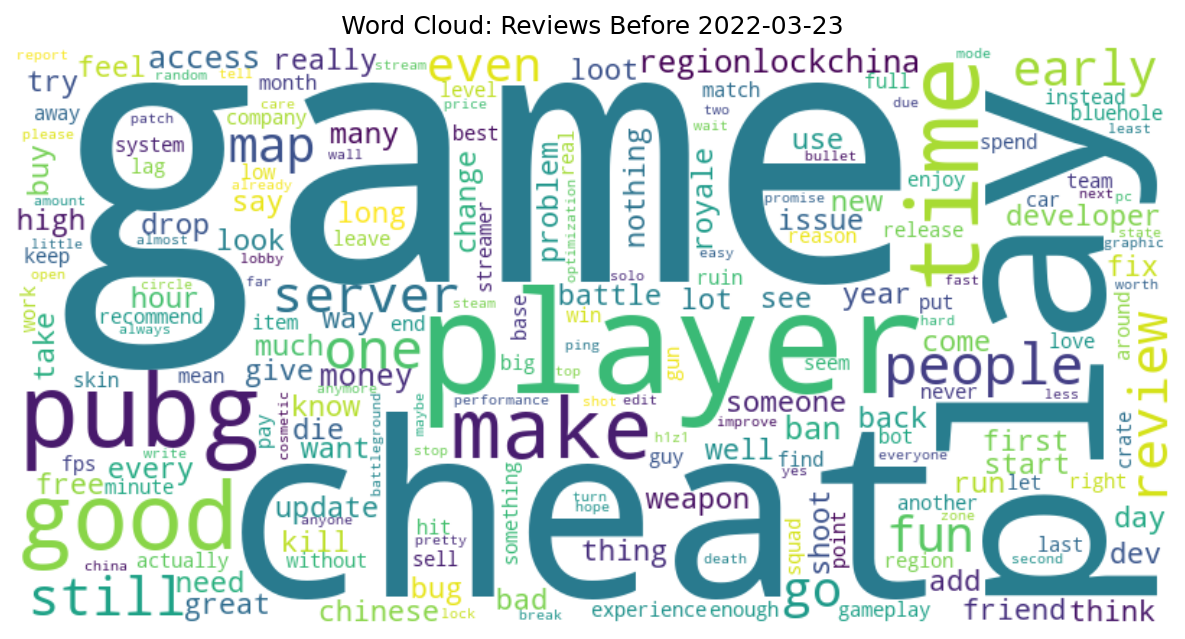

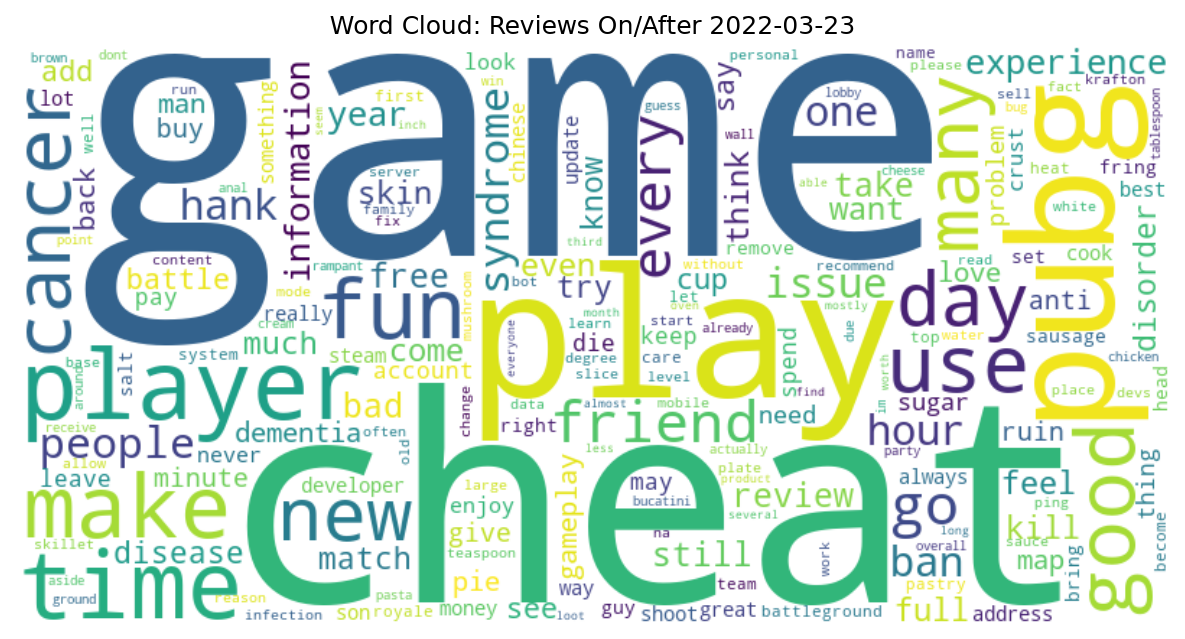

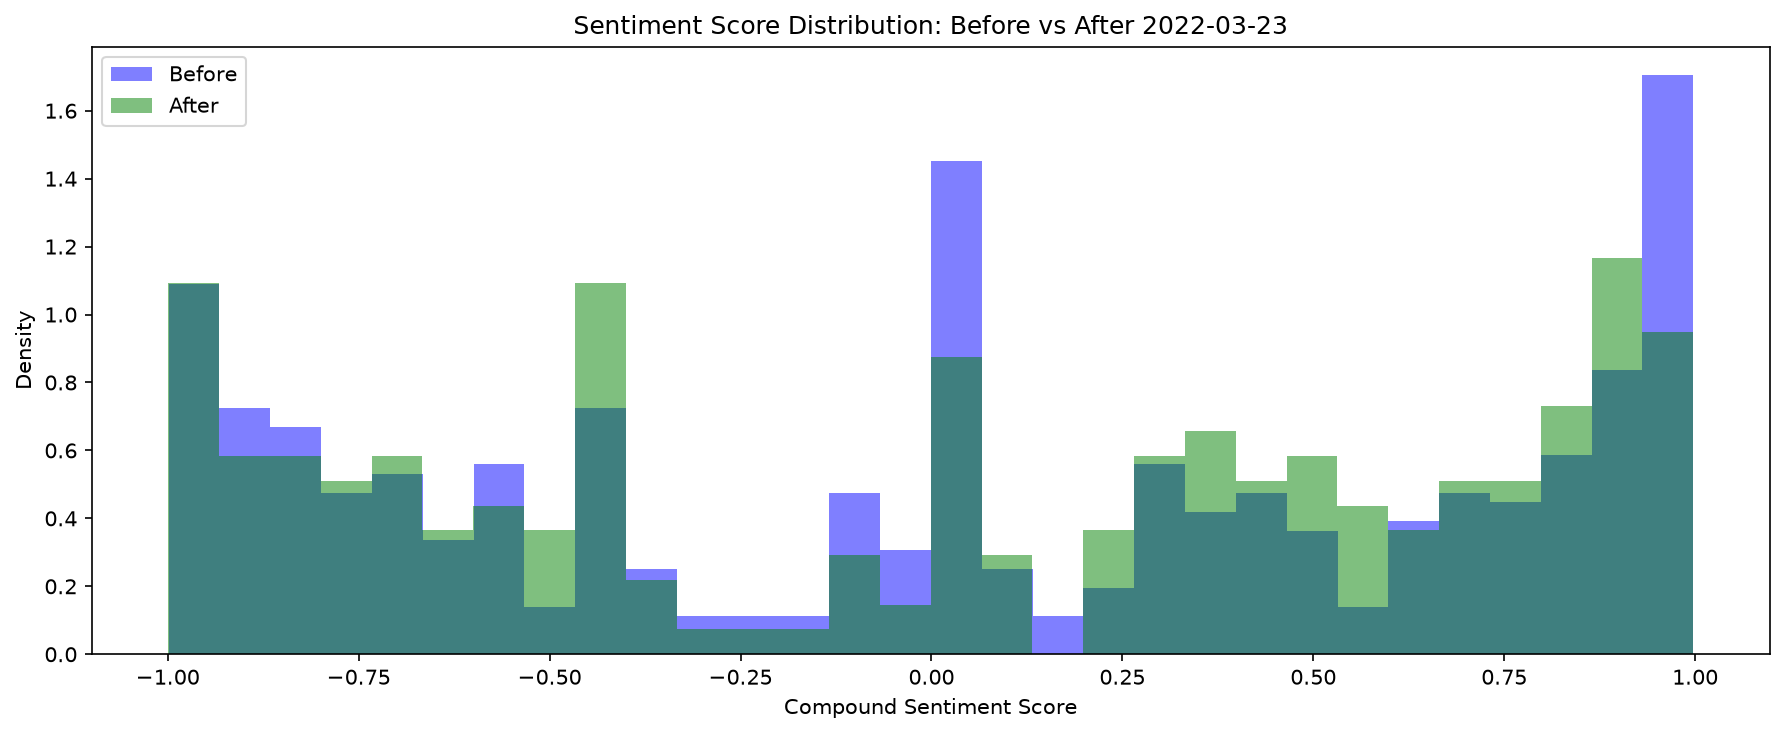

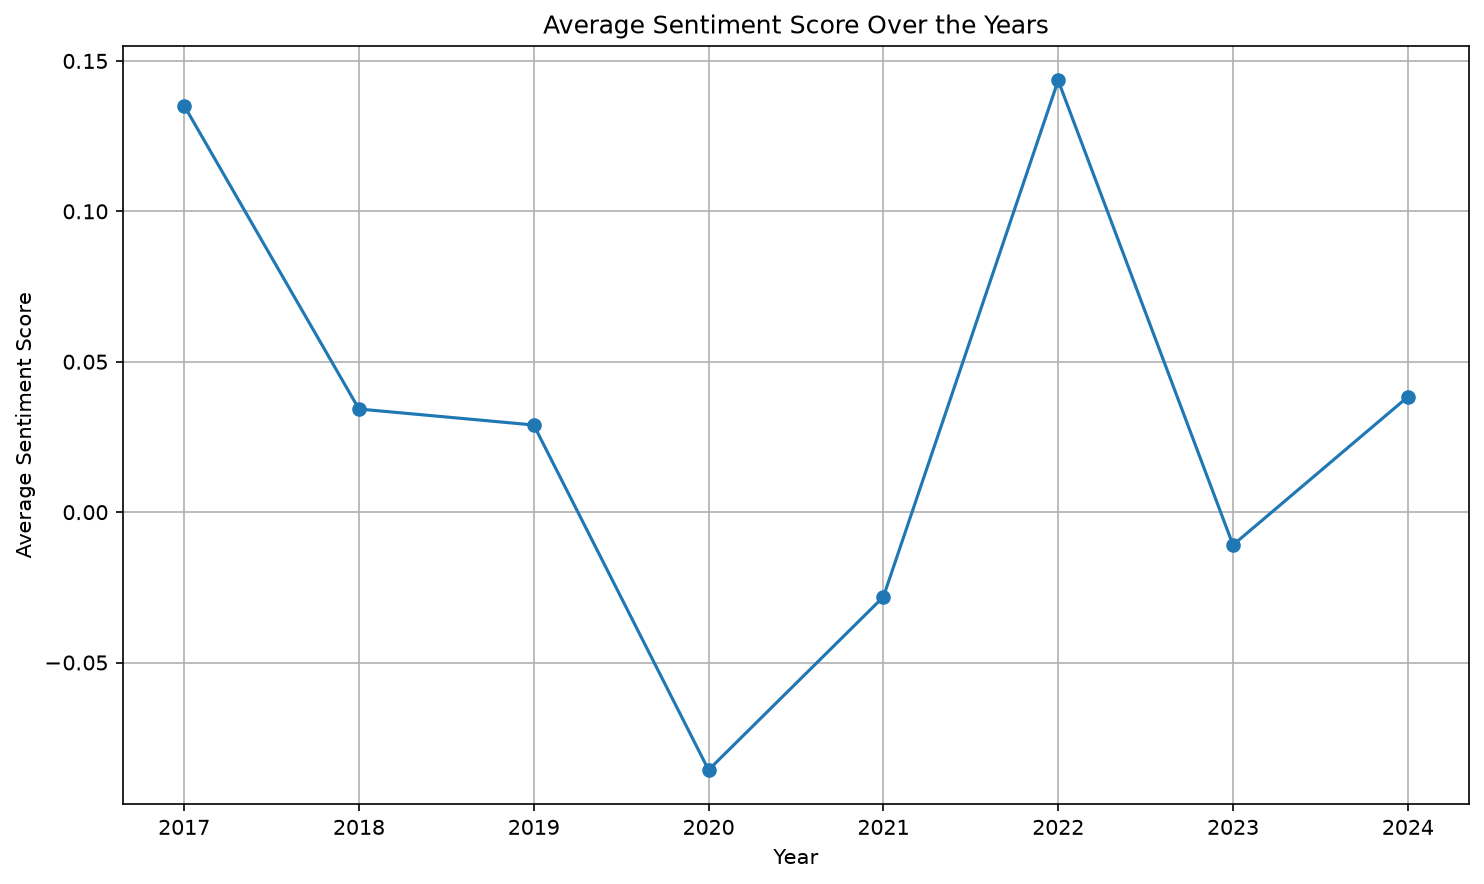

In [11]:
for name in ("wordcloud_before", "wordcloud_after", "sentiment_distribution", "sentiment_yearly"):
    display(Image(filename=report.figures[name], width=750))

In [12]:
print(f"{len(report.tables)} tables:", *sorted(p.name for p in report.tables.values()), sep="\n  ")
print(f"\n{len(report.figures)} figures:", *sorted(p.name for p in report.figures.values()), sep="\n  ")

8 tables:
  correlations.csv
  documents.csv
  metadata.csv
  sentiment.csv
  summary.json
  word_frequencies_after.csv
  word_frequencies_before.csv
  word_frequencies_overall.csv

24 figures:
  distribution_fit_after.png
  distribution_fit_before.png
  sentiment_boxplot.png
  sentiment_categories.png
  sentiment_distribution.png
  sentiment_engagement_boxplot.png
  sentiment_vs_hours.png
  sentiment_vs_recommendation.png
  sentiment_vs_votes.png
  sentiment_yearly.png
  word_frequencies_after.png
  word_frequencies_before.png
  word_frequencies_overall.png
  wordcloud_after.png
  wordcloud_before.png
  wordcloud_overall.png
  wordcloud_year_2017.png
  wordcloud_year_2018.png
  wordcloud_year_2019.png
  wordcloud_year_2020.png
  wordcloud_year_2021.png
  wordcloud_year_2022.png
  wordcloud_year_2023.png
  wordcloud_year_2024.png


## The same from the command line

Every step above has a CLI command. Here we call the CLI through the current Python
interpreter so it works without activating anything; in a terminal you would simply type
`steam-review-analysis ...`.

In [13]:
def cli(*args: str) -> None:
    """Run `steam-review-analysis <args>` and print its output."""
    command = [sys.executable, "-m", "steam_review_analysis", "--data-dir", str(DATA_DIR), *args]
    result = subprocess.run(command, capture_output=True, text=True, cwd=PROJECT_ROOT)
    print(result.stdout or result.stderr)


cli("analyse", "games")

2026-11-19 15:11:40,696 INFO steam_review_analysis.analysis.cli: Counter-Strike 2 (app 730): 757 reviews
2026-11-19 15:11:40,696 INFO steam_review_analysis.analysis.cli: PUBG: BATTLEGROUNDS (app 578080): 757 reviews
2026-11-19 15:11:40,696 INFO steam_review_analysis.analysis.cli: The Sims 4 (app 1222670): 606 reviews



In [14]:
# Same report as above, driven by the preset (cutoff and word rules come from presets.toml).
cli("analyse", "report", "--game", "578080", "--preset", "PUBG")

2026-11-19 15:12:17,050 INFO steam_review_analysis.analysis.cli: Analysed PUBG: BATTLEGROUNDS: 744 reviews, 8 tables, 24 figures in C:\Users\mateu\Desktop\app_aml\data\processed\analysis\pubg_battlegrounds



## Next steps

- **02_event_impact_across_games** uses the individual functions behind `run_analysis` to
  compare how three games' reviews changed after a major business-model change.
- **03_sentiment_models** checks how well VADER and the transformer models predict the
  reviewer's own recommendation.